In [1]:
import sys
sys.path.insert(0, "..")

from utils.modelling import *
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

In [2]:
Xtrain, ytrain, Xval, yval, Xtest, ytest = load_train_val_test('../data/processed/dataset.csv')

In [3]:
preprocessor_A = make_preprocessor(model="A").set_params(sparse_threshold=0)
Xtrain_prepared = preprocessor_A.fit_transform(Xtrain)
feature_names = preprocessor_A.get_feature_names_out()

pca = PCA(random_state=67).fit(Xtrain_prepared)
explained = np.cumsum(pca.explained_variance_ratio_)

print(f"features after preprocessing: {Xtrain_prepared.shape[1]}")
for share in [0.5, 0.8, 0.9, 0.95, 0.99]:
    print(f"{share:.0%} of variance needs {np.searchsorted(explained, share) + 1} components")

features after preprocessing: 101
50% of variance needs 5 components
80% of variance needs 16 components
90% of variance needs 28 components
95% of variance needs 39 components
99% of variance needs 56 components


In [4]:
loadings = pd.DataFrame(pca.components_[:3].T, index=feature_names, columns=["PC1", "PC2", "PC3"])

for i, pc in enumerate(loadings.columns):
    print(f"{pc}: {pca.explained_variance_ratio_[i]:.1%} of variance")
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(8)
    print(top.round(3).to_string(), "\n")

PC1: 15.4% of variance
num__missingindicator_HEIGHT              0.463
num__missingindicator_SPEED               0.431
num__missingindicator_DISTANCE            0.339
num__HEIGHT                              -0.254
num__DISTANCE                            -0.240
num__missingindicator_log_ImpactEnergy    0.236
nom__SKY_missing                          0.184
nom__PRECIPITATION_missing                0.184 

PC2: 12.0% of variance
num__SPEED                                0.462
num__HEIGHT                               0.397
num__DISTANCE                             0.361
num__missingindicator_BodyMass            0.330
num__missingindicator_log_ImpactEnergy    0.308
num__AC_MASS                              0.255
num__BodyMass                            -0.230
num__NUM_ENGS                             0.211 

PC3: 9.1% of variance
num__AC_MASS                              0.465
num__missingindicator_BodyMass           -0.449
num__NUM_ENGS                             0.416
num__BodyMass   

In [5]:
weights = make_class_weights(ytrain)
N_COMPONENTS = [None, 5, 10, 20, 40, 60]

def make_pca_model(classifier, n_components=None):
    steps = [make_preprocessor(model="A").set_params(sparse_threshold=0)]
    if n_components is not None:
        steps.append(PCA(n_components=n_components, random_state=67))
    steps.append(classifier)
    return make_pipeline(*steps)

classifiers = {
    "Logistic regression": lambda: LogisticRegression(class_weight=weights(0.5), max_iter=1000),
    "Decision tree": lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight=weights(0.25), random_state=67),
}

pca_results = []
for name, classifier in classifiers.items():
    for n in N_COMPONENTS:
        model = make_pca_model(classifier(), n)
        scores = cross_val_score(model, Xtrain, ytrain, cv=5, scoring="f1_macro", n_jobs=-1)
        model.fit(Xtrain, ytrain)
        val_f1 = f1_score(yval, model.predict(Xval), average="macro")
        pca_results.append({"model": name, "n_components": "no PCA" if n is None else n, "cv_f1_mean": scores.mean(), "cv_f1_std": scores.std(), "val_f1_macro": val_f1})
        print(pca_results[-1])

pca_results = pd.DataFrame(pca_results)
pca_results.to_csv("../results/pca.csv", index=False)
pca_results

{'model': 'Logistic regression', 'n_components': 'no PCA', 'cv_f1_mean': np.float64(0.48400054660005837), 'cv_f1_std': np.float64(0.008462619377905772), 'val_f1_macro': 0.47265309583102955}


{'model': 'Logistic regression', 'n_components': 5, 'cv_f1_mean': np.float64(0.42141029776995287), 'cv_f1_std': np.float64(0.009919622442524157), 'val_f1_macro': 0.416306017573364}


{'model': 'Logistic regression', 'n_components': 10, 'cv_f1_mean': np.float64(0.4300674749851545), 'cv_f1_std': np.float64(0.004990468310200873), 'val_f1_macro': 0.4202629857108963}


{'model': 'Logistic regression', 'n_components': 20, 'cv_f1_mean': np.float64(0.44537056932008434), 'cv_f1_std': np.float64(0.0030014920751493877), 'val_f1_macro': 0.43409330196758056}


{'model': 'Logistic regression', 'n_components': 40, 'cv_f1_mean': np.float64(0.473289111986091), 'cv_f1_std': np.float64(0.011367056436901252), 'val_f1_macro': 0.4628618978989166}


{'model': 'Logistic regression', 'n_components': 60, 'cv_f1_mean': np.float64(0.4787350810667581), 'cv_f1_std': np.float64(0.009561937372341891), 'val_f1_macro': 0.4681715896443754}


... (3 outputs left out)

{'model': 'Decision tree', 'n_components': 20, 'cv_f1_mean': np.float64(0.4414202295974901), 'cv_f1_std': np.float64(0.009968481187794911), 'val_f1_macro': 0.41306210408627225}


{'model': 'Decision tree', 'n_components': 40, 'cv_f1_mean': np.float64(0.45073472997605124), 'cv_f1_std': np.float64(0.012160925148396185), 'val_f1_macro': 0.44977000802677086}


{'model': 'Decision tree', 'n_components': 60, 'cv_f1_mean': np.float64(0.44378928705269727), 'cv_f1_std': np.float64(0.008032614708079191), 'val_f1_macro': 0.44415913891804876}


,model,n_components,cv_f1_mean,cv_f1_std,val_f1_macro
0,Logistic regression,no PCA,0.484001,0.008463,0.472653
1,Logistic regression,5,0.421410,0.009920,0.416306
2,Logistic regression,10,0.430067,0.004990,0.420263
3,Logistic regression,20,0.445371,0.003001,0.434093
4,Logistic regression,40,0.473289,0.011367,0.462862
5,Logistic regression,60,0.478735,0.009562,0.468172
6,Decision tree,no PCA,0.474618,0.017286,0.453685
7,Decision tree,5,0.430249,0.012326,0.419390
8,Decision tree,10,0.437867,0.009584,0.436287
9,Decision tree,20,0.441420,0.009968,0.413062


## plots

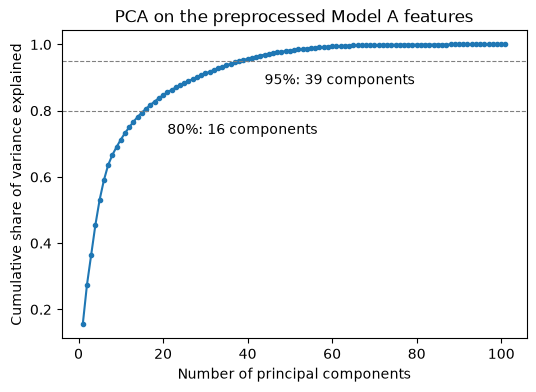

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(explained) + 1), explained, marker=".")
for share in [0.8, 0.95]:
    n = np.searchsorted(explained, share) + 1
    ax.axhline(share, color="grey", linestyle="--", linewidth=0.8)
    ax.annotate(f"{share:.0%}: {n} components", (n, share), xytext=(n + 5, share - 0.07))
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative share of variance explained")
ax.set_title("PCA on the preprocessed Model A features")
fig.savefig("../plots/pca_explained_variance.png", dpi=200, bbox_inches="tight")

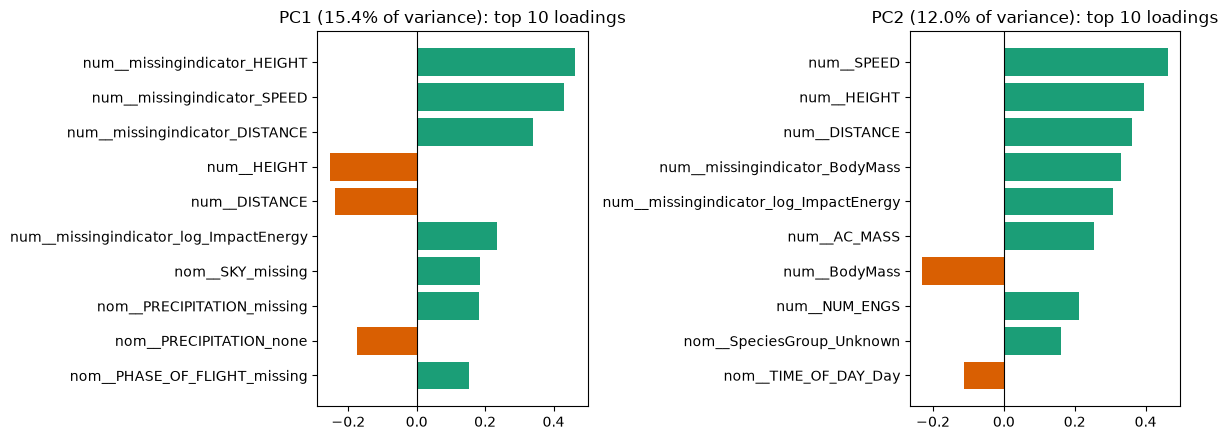

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(10)[::-1]
    ax.barh(top.index, top.values, color=["#d95f02" if v < 0 else "#1b9e77" for v in top.values])
    ax.set_title(f"{pc} ({pca.explained_variance_ratio_[int(pc[2]) - 1]:.1%} of variance): top 10 loadings")
    ax.axvline(0, color="black", linewidth=0.8)
fig.tight_layout()
fig.savefig("../plots/pca_loadings.png", dpi=200, bbox_inches="tight")

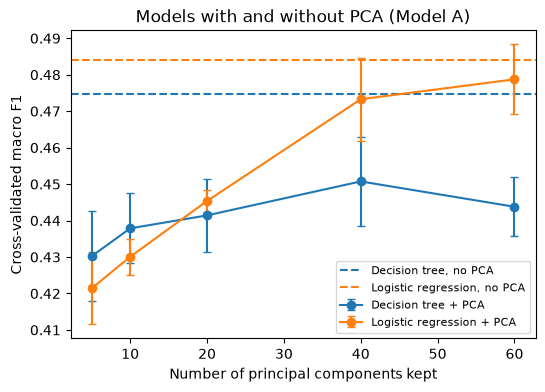

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, group in pca_results.groupby("model"):
    with_pca = group[group["n_components"] != "no PCA"]
    line = ax.errorbar(with_pca["n_components"].astype(int), with_pca["cv_f1_mean"], yerr=with_pca["cv_f1_std"], marker="o", capsize=3, label=f"{name} + PCA")
    ax.axhline(group[group["n_components"] == "no PCA"]["cv_f1_mean"].iloc[0], color=line[0].get_color(), linestyle="--", label=f"{name}, no PCA")
ax.set_xlabel("Number of principal components kept")
ax.set_ylabel("Cross-validated macro F1")
ax.set_title("Models with and without PCA (Model A)")
ax.legend(fontsize=8)
fig.savefig("../plots/pca_models.png", dpi=200, bbox_inches="tight")